# 01. Análise Exploratória de Dados (EDA) — Voo Regular Ativo (VRA / ANAC)
## Trabalho Prático de Deep Learning (2026/2) — Prof. Dr. Sérgio Canuto
**Objetivo:** Inspecionar a estrutura dos microdados, avaliar a distribuição da variável alvo, identificar frequências de voos por companhia aérea e aeroporto, analisar nulos/anomalias e comprovar a blindagem contra Data Leakage.


In [1]:
import sys
import os
for p in ['.', '..', '../..']:
    if os.path.abspath(p) not in sys.path:
        sys.path.insert(0, os.path.abspath(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_pipeline import load_vra_dataset
from src.generate_sample_vra import generate_sample_vra_dataset

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)


### 1. Carga dos Dados Brutos do VRA
Se a base em `data/raw/` não existir, geramos a amostra estrutural reprodutível.


In [2]:
data_path = 'data/raw/vra_amostra_2023.csv' if os.path.exists('data/raw/vra_amostra_2023.csv') else '../data/raw/vra_amostra_2023.csv'
if not os.path.exists(data_path):
    generate_sample_vra_dataset(data_path, n_samples=6000)

df_raw = load_vra_dataset(data_path)
print(f"Dimensões do dataset bruto: {df_raw.shape}")
df_raw.head()


Dimensões do dataset bruto: (6000, 12)


,ICAOEmpresaAerea,NumeroVoo,CodigoDI,CodigoTipoLinha,ICAOAerodromoOrigem,ICAOAerodromoDestino,PartidaPrevista,PartidaReal,ChegadaPrevista,ChegadaReal,SituacaoVoo,CodigoJustificativa
0,GLO,9322,0,R,SBPA,SBRJ,2023-01-01 06:00:00,2023-01-01 06:36:31,2023-01-01 08:27:00,2023-01-01 08:57:05,REALIZADO,CONGESTIONAMENTO AEROPORTUÁRIO
1,ONE,2184,0,I,SBKP,SBGR,2023-01-01 06:21:32,NaN,2023-01-01 10:17:32,NaN,CANCELADO,METEOROLOGIA ADVERSA
2,GLO,1189,0,N,SBFZ,SBBR,2023-01-01 06:43:04,2023-01-01 09:05:28,2023-01-01 08:26:04,2023-01-01 10:44:25,REALIZADO,CONGESTIONAMENTO AEROPORTUÁRIO
3,GLO,9792,0,I,SBCF,SBSV,2023-01-01 07:04:36,2023-01-01 07:02:15,2023-01-01 09:59:36,2023-01-01 09:55:06,REALIZADO,NaN
4,GLO,1775,0,N,SBSV,SBFZ,2023-01-01 07:26:08,2023-01-01 07:17:57,2023-01-01 09:40:08,2023-01-01 09:29:09,REALIZADO,NaN


### 2. Diagnóstico de Nulos, Tipos e Situação Operacional


In [3]:
print("Tipos de Dados:")
print(df_raw.dtypes)
print("\nContagem de Valores Ausentes:")
print(df_raw.isnull().sum())
print("\nDistribuição da Situação de Voo:")
print(df_raw['SituacaoVoo'].value_counts(dropna=False))


Tipos de Dados:
ICAOEmpresaAerea          str
NumeroVoo               int64
CodigoDI                int64
CodigoTipoLinha           str
ICAOAerodromoOrigem       str
ICAOAerodromoDestino      str
PartidaPrevista           str
PartidaReal               str
ChegadaPrevista           str
ChegadaReal               str
SituacaoVoo               str
CodigoJustificativa       str
dtype: object

Contagem de Valores Ausentes:
ICAOEmpresaAerea           0
NumeroVoo                  0
CodigoDI                   0
CodigoTipoLinha            0
ICAOAerodromoOrigem        0
ICAOAerodromoDestino       0
PartidaPrevista            0
PartidaReal              247
ChegadaPrevista            0
ChegadaReal              247
SituacaoVoo                0
CodigoJustificativa     4615
dtype: int64

Distribuição da Situação de Voo:
SituacaoVoo
REALIZADO    5753
CANCELADO     247
Name: count, dtype: int64


### 3. Distribuição das Principais Concessionárias e Aeródromos


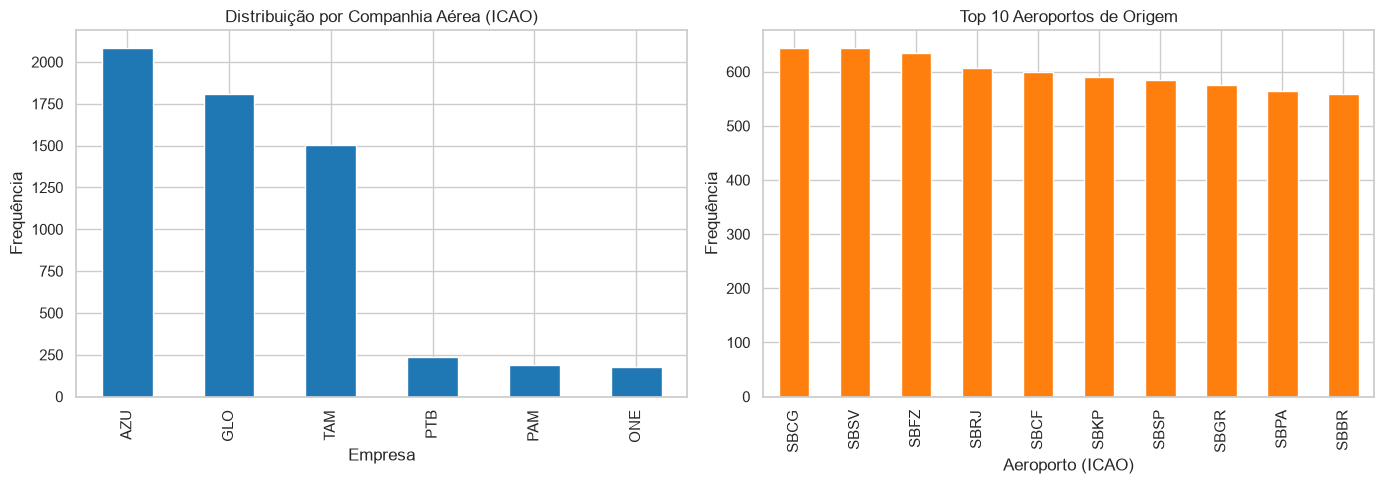

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top Companhias Aéreas
df_raw['ICAOEmpresaAerea'].value_counts().plot(kind='bar', ax=axes[0], color='#1f77b4')
axes[0].set_title('Distribuição por Companhia Aérea (ICAO)')
axes[0].set_xlabel('Empresa')
axes[0].set_ylabel('Frequência')

# Top Aeródromos de Origem
df_raw['ICAOAerodromoOrigem'].value_counts().head(10).plot(kind='bar', ax=axes[1], color='#ff7f0e')
axes[1].set_title('Top 10 Aeroportos de Origem')
axes[1].set_xlabel('Aeroporto (ICAO)')
axes[1].set_ylabel('Frequência')

plt.tight_layout()
plt.show()


### 4. Formulação da Variável Alvo e Análise de Desbalanceamento
Atraso crítico é definido para pousos com atraso superior a 15 minutos ($>15$ min).


Classe 0 (Pontual <= 15 min): 4536 (78.8%)
Classe 1 (Atrasado > 15 min): 1217 (21.2%)


C:\Users\User\AppData\Local\Temp\ipykernel_33228\2085713068.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='AlvoBinario', data=df_valid, palette=['#2ca02c', '#d62728'])


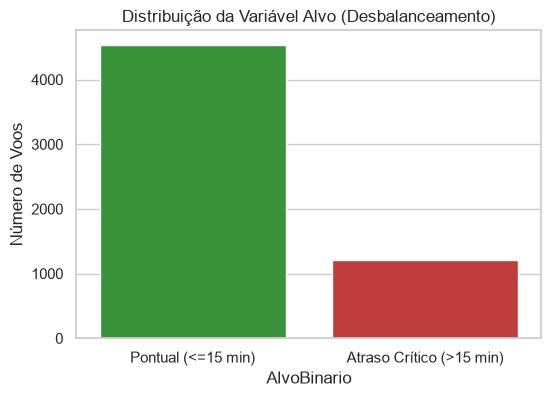

In [5]:
df_valid = df_raw.dropna(subset=['PartidaPrevista', 'ChegadaPrevista', 'ChegadaReal']).copy()
df_valid['PartidaPrevista'] = pd.to_datetime(df_valid['PartidaPrevista'])
df_valid['ChegadaPrevista'] = pd.to_datetime(df_valid['ChegadaPrevista'])
df_valid['ChegadaReal'] = pd.to_datetime(df_valid['ChegadaReal'])

df_valid['AtrasoChegadaMin'] = (df_valid['ChegadaReal'] - df_valid['ChegadaPrevista']).dt.total_seconds() / 60.0
df_valid['AlvoBinario'] = (df_valid['AtrasoChegadaMin'] > 15).astype(int)

counts = df_valid['AlvoBinario'].value_counts()
pcts = df_valid['AlvoBinario'].value_counts(normalize=True) * 100

print(f"Classe 0 (Pontual <= 15 min): {counts[0]} ({pcts[0]:.1f}%)")
print(f"Classe 1 (Atrasado > 15 min): {counts[1]} ({pcts[1]:.1f}%)")

plt.figure(figsize=(6, 4))
sns.countplot(x='AlvoBinario', data=df_valid, palette=['#2ca02c', '#d62728'])
plt.title('Distribuição da Variável Alvo (Desbalanceamento)')
plt.xticks([0, 1], ['Pontual (<=15 min)', 'Atraso Crítico (>15 min)'])
plt.ylabel('Número de Voos')
plt.show()


### 5. Justificativa Anti-Leakage
Conforme a Seção 2.1 e 2.2 do Edital, as variáveis `ChegadaReal`, `CodigoJustificativa` e `SituacaoVoo` são eliminadas da matriz de características $X$, visto que só são conhecidas após a conclusão da operação.
